In [5]:
!pip install -q pandas numpy scikit-learn mlflow matplotlib seaborn joblib

In [1]:

import pandas as pd
import os

train_path = "/content/cleaned_ASAG2024_train.csv"
test_path = "/content/cleaned_ASAG2024_test.csv"

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("Training Dataset Shape:", train_df.shape)
print("External Test Dataset Shape:", test_df.shape)

print("\nTraining Columns:")
print(train_df.columns.tolist())

print("\nExternal Test Columns:")
print(test_df.columns.tolist())


Training Dataset Shape: (11149, 11)
External Test Dataset Shape: (1898, 11)

Training Columns:
['question', 'provided_answer', 'reference_answer', 'grade', 'data_source', 'normalized_grade', 'weight', 'index', 'answer_word_count', 'reference_word_count', 'answer_reference_ratio']

External Test Columns:
['question', 'provided_answer', 'reference_answer', 'grade', 'data_source', 'normalized_grade', 'weight', 'index', 'answer_word_count', 'reference_word_count', 'answer_reference_ratio']


In [2]:

FEATURES = [
    "answer_word_count",
    "reference_word_count",
    "answer_reference_ratio"
]

TARGET = "normalized_grade"

X = train_df[FEATURES]
y = train_df[TARGET]

X_external = test_df[FEATURES]
y_external = test_df[TARGET]

print("Training Features:", X.shape)
print("Training Target:", y.shape)

print("External Test Features:", X_external.shape)
print("External Test Target:", y_external.shape)

print("\nMissing Values:")
print(X.isnull().sum())
print("Target Missing Values:", y.isnull().sum())


Training Features: (11149, 3)
Training Target: (11149,)
External Test Features: (1898, 3)
External Test Target: (1898,)

Missing Values:
answer_word_count         1
reference_word_count      1
answer_reference_ratio    1
dtype: int64
Target Missing Values: 1


In [3]:

from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Set:", X_train.shape)
print("Validation Set:", X_val.shape)
print("External Test Set:", X_external.shape)


Training Set: (8919, 3)
Validation Set: (2230, 3)
External Test Set: (1898, 3)


In [9]:

# Remove rows with missing target values only
train_df = train_df.dropna(subset=["normalized_grade"]).copy()

# Recreate features and target
X = train_df[FEATURES]
y = train_df[TARGET]

# Recreate train-validation split
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Updated Training Dataset:", train_df.shape)
print("Training Set:", X_train.shape)
print("Validation Set:", X_val.shape)
print("Missing Target Values:", y.isnull().sum())


Updated Training Dataset: (11148, 11)
Training Set: (8918, 3)
Validation Set: (2230, 3)
Missing Target Values: 0


In [10]:
import mlflow
import os

PROJECT_DIR = "/content/random_forest_backup"

DB_DIR = f"{PROJECT_DIR}/database"
ARTIFACT_DIR = f"{PROJECT_DIR}/mlartifacts"
MODEL_DIR = f"{PROJECT_DIR}/models"
RESULT_DIR = f"{PROJECT_DIR}/results"

os.makedirs(DB_DIR, exist_ok=True)
os.makedirs(ARTIFACT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

DB_PATH = f"{DB_DIR}/random_forest_tracking.db"

mlflow.set_tracking_uri(f"sqlite:///{DB_PATH}")

EXPERIMENT_NAME = "Automated_Answer_Grading_RandomForest"

mlflow.set_experiment(EXPERIMENT_NAME)

print("MLflow Initialized Successfully")
print("Tracking URI:", mlflow.get_tracking_uri())
print("Database:", DB_PATH)
print("Experiment:", EXPERIMENT_NAME)


MLflow Initialized Successfully
Tracking URI: sqlite:////content/random_forest_backup/database/random_forest_tracking.db
Database: /content/random_forest_backup/database/random_forest_tracking.db
Experiment: Automated_Answer_Grading_RandomForest


In [12]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import ParameterSampler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import mlflow
import joblib
import json
import os
import time

# Hyperparameter search space
param_distributions = {
    "n_estimators": [100, 150, 200, 300, 400],
    "max_depth": [5, 10, 15, 20, 30, None],
    "min_samples_split": [2, 5, 10, 15],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": [1.0, "sqrt", "log2"],
    "bootstrap": [True, False],
    "criterion": ["squared_error", "friedman_mse"]
}

# Generate 30 different configurations
configurations = list(ParameterSampler(
    param_distributions,
    n_iter=30,
    random_state=42
))

experiment_results = []

best_mae = float("inf")
best_model = None
best_params = None

mlflow.set_experiment("Automated_Answer_Grading_RandomForest")

start_time = time.time()

for i, params in enumerate(configurations, 1):

    with mlflow.start_run(run_name=f"RF_Experiment_{i:02d}"):

        model = RandomForestRegressor(
            **params,
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_train, y_train)

        predictions = model.predict(X_val)

        mae = mean_absolute_error(y_val, predictions)
        rmse = np.sqrt(mean_squared_error(y_val, predictions))
        r2 = r2_score(y_val, predictions)

        mlflow.log_params({
            k: str(v) if v is None else v
            for k, v in params.items()
        })

        mlflow.log_metric("MAE", mae)
        mlflow.log_metric("RMSE", rmse)
        mlflow.log_metric("R2", r2)

        mlflow.set_tag("algorithm", "RandomForestRegressor")
        mlflow.set_tag("dataset", "ASAG2024")

        experiment_results.append({
            "Run": i,
            **params,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

        if mae < best_mae:
            best_mae = mae
            best_model = model
            best_params = params.copy()

        print(
            f"Run {i:02d}/30 | "
            f"MAE: {mae:.4f} | "
            f"RMSE: {rmse:.4f} | "
            f"R2: {r2:.4f}"
        )

# Save experiment results
results_df = pd.DataFrame(experiment_results)
results_df = results_df.sort_values("MAE").reset_index(drop=True)

results_df.to_csv(
    f"{PROJECT_DIR}/results/experiment_results.csv",
    index=False
)

# Save best model and parameters
joblib.dump(
    best_model,
    f"{PROJECT_DIR}/models/best_model.pkl"
)

with open(f"{PROJECT_DIR}/results/best_parameters.json", "w") as f:
    json.dump(best_params, f, indent=4)

print("\n========== EXPERIMENT SUMMARY ==========")
print("Total Runs:", len(experiment_results))
print("Best MAE:", best_mae)
print("Best Parameters:", best_params)
print("Total Time:", round(time.time() - start_time, 2), "seconds")

display(results_df)


Run 01/30 | MAE: 0.3017 | RMSE: 0.3599 | R2: 0.0662
Run 02/30 | MAE: 0.3043 | RMSE: 0.3678 | R2: 0.0243
Run 03/30 | MAE: 0.3045 | RMSE: 0.3688 | R2: 0.0190
Run 04/30 | MAE: 0.3016 | RMSE: 0.3617 | R2: 0.0566
Run 05/30 | MAE: 0.3042 | RMSE: 0.3679 | R2: 0.0239
Run 06/30 | MAE: 0.3047 | RMSE: 0.3591 | R2: 0.0701
Run 07/30 | MAE: 0.3031 | RMSE: 0.3654 | R2: 0.0374
Run 08/30 | MAE: 0.3012 | RMSE: 0.3575 | R2: 0.0786
Run 09/30 | MAE: 0.3056 | RMSE: 0.3713 | R2: 0.0058
Run 10/30 | MAE: 0.3049 | RMSE: 0.3591 | R2: 0.0701
Run 11/30 | MAE: 0.3031 | RMSE: 0.3679 | R2: 0.0239
Run 12/30 | MAE: 0.3038 | RMSE: 0.3673 | R2: 0.0270
Run 13/30 | MAE: 0.3032 | RMSE: 0.3637 | R2: 0.0464
Run 14/30 | MAE: 0.3049 | RMSE: 0.3605 | R2: 0.0630
Run 15/30 | MAE: 0.3045 | RMSE: 0.3588 | R2: 0.0719
Run 16/30 | MAE: 0.2999 | RMSE: 0.3577 | R2: 0.0773
Run 17/30 | MAE: 0.3013 | RMSE: 0.3623 | R2: 0.0535
Run 18/30 | MAE: 0.3015 | RMSE: 0.3598 | R2: 0.0663
Run 19/30 | MAE: 0.3050 | RMSE: 0.3695 | R2: 0.0155
Run 20/30 | 

,Run,n_estimators,min_samples_split,min_samples_leaf,max_features,max_depth,criterion,bootstrap,MAE,RMSE,R2
0,16,100,5,1,1.0,10.0,friedman_mse,True,0.299929,0.357721,0.077267
1,29,400,10,8,log2,10.0,squared_error,True,0.300825,0.357200,0.079956
2,8,150,5,8,log2,10.0,squared_error,True,0.301156,0.357462,0.078602
3,17,400,5,4,1.0,20.0,squared_error,True,0.301326,0.362303,0.053476
4,23,400,2,8,log2,30.0,squared_error,True,0.301406,0.359779,0.066623
5,18,150,10,8,log2,20.0,friedman_mse,True,0.301488,0.359844,0.066285
6,4,150,10,8,sqrt,20.0,friedman_mse,False,0.301579,0.361705,0.056600
7,20,300,10,2,1.0,30.0,friedman_mse,True,0.301579,0.363553,0.046937
8,30,200,2,4,sqrt,30.0,squared_error,True,0.301604,0.361691,0.056674
9,1,100,2,8,sqrt,20.0,squared_error,True,0.301664,0.359855,0.066224


In [13]:

# Save best model
BEST_MODEL_PATH = f"{PROJECT_DIR}/models/best_model.pkl"

joblib.dump(best_model, BEST_MODEL_PATH)

# Save best configuration
best_results = results_df.iloc[0]

print("Best Model Saved Successfully")
print("Model Path:", BEST_MODEL_PATH)
print("\nBest Hyperparameters:")
print(best_params)

print("\nBest Validation Metrics:")
print("MAE:", best_results["MAE"])
print("RMSE:", best_results["RMSE"])
print("R2:", best_results["R2"])


Best Model Saved Successfully
Model Path: /content/random_forest_backup/models/best_model.pkl

Best Hyperparameters:
{'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': 10, 'criterion': 'friedman_mse', 'bootstrap': True}

Best Validation Metrics:
MAE: 0.2999291401859148
RMSE: 0.3577212029614427
R2: 0.0772670428325779


In [14]:

# Load saved best model
best_model = joblib.load(
    f"{PROJECT_DIR}/models/best_model.pkl"
)

# Predict on external test dataset
external_predictions = best_model.predict(X_external)

# Calculate final metrics
external_mae = mean_absolute_error(
    y_external, external_predictions
)

external_rmse = np.sqrt(
    mean_squared_error(y_external, external_predictions)
)

external_r2 = r2_score(
    y_external, external_predictions
)

print("========== EXTERNAL TEST RESULTS ==========")
print("Test Records:", len(y_external))
print("MAE:", round(external_mae, 4))
print("RMSE:", round(external_rmse, 4))
print("R2 Score:", round(external_r2, 4))

# Save external evaluation results
external_results = pd.DataFrame([{
    "Model": "Random Forest Regressor",
    "MAE": external_mae,
    "RMSE": external_rmse,
    "R2": external_r2
}])

external_results.to_csv(
    f"{PROJECT_DIR}/results/external_test_metrics.csv",
    index=False
)

print("\nExternal test results saved successfully.")


========== EXTERNAL TEST RESULTS ==========
Test Records: 1898
MAE: 0.2995
RMSE: 0.3572
R2 Score: 0.1033

External test results saved successfully.


In [15]:

# Log external test evaluation in MLflow
with mlflow.start_run(run_name="Final_External_Test_Evaluation"):

    mlflow.log_params({
        f"best_{key}": str(value)
        for key, value in best_params.items()
    })

    mlflow.log_metric("External_MAE", external_mae)
    mlflow.log_metric("External_RMSE", external_rmse)
    mlflow.log_metric("External_R2", external_r2)

    mlflow.set_tag("evaluation", "external_test")
    mlflow.set_tag("algorithm", "RandomForestRegressor")

    mlflow.log_artifact(
        f"{PROJECT_DIR}/results/external_test_metrics.csv"
    )

print("External Test Metrics Logged to MLflow Successfully")

experiment = mlflow.get_experiment_by_name(
    "Automated_Answer_Grading_RandomForest"
)

print("Experiment ID:", experiment.experiment_id)
print("Artifact Location:", experiment.artifact_location)


External Test Metrics Logged to MLflow Successfully
Experiment ID: 1
Artifact Location: /content/mlruns/1


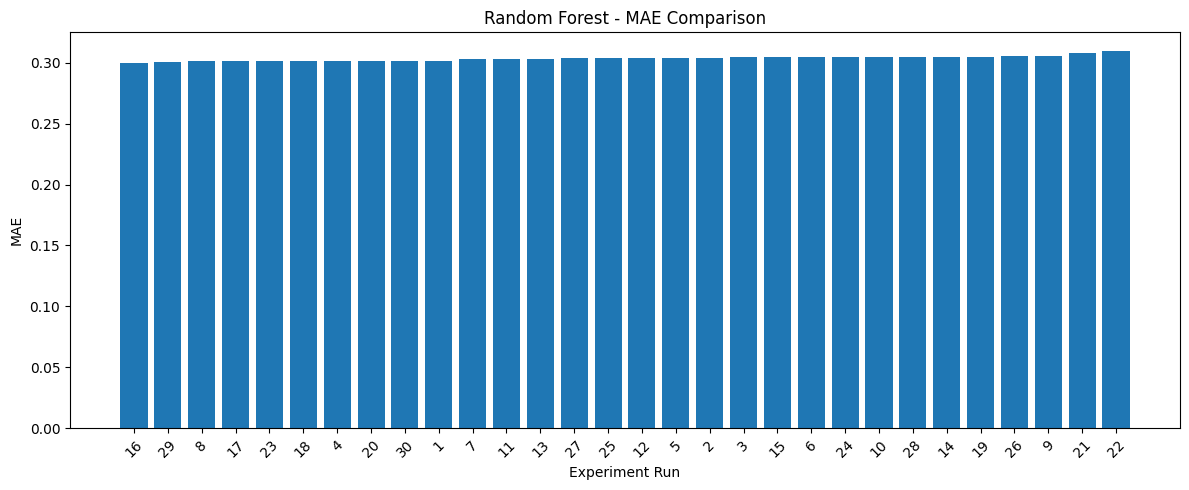

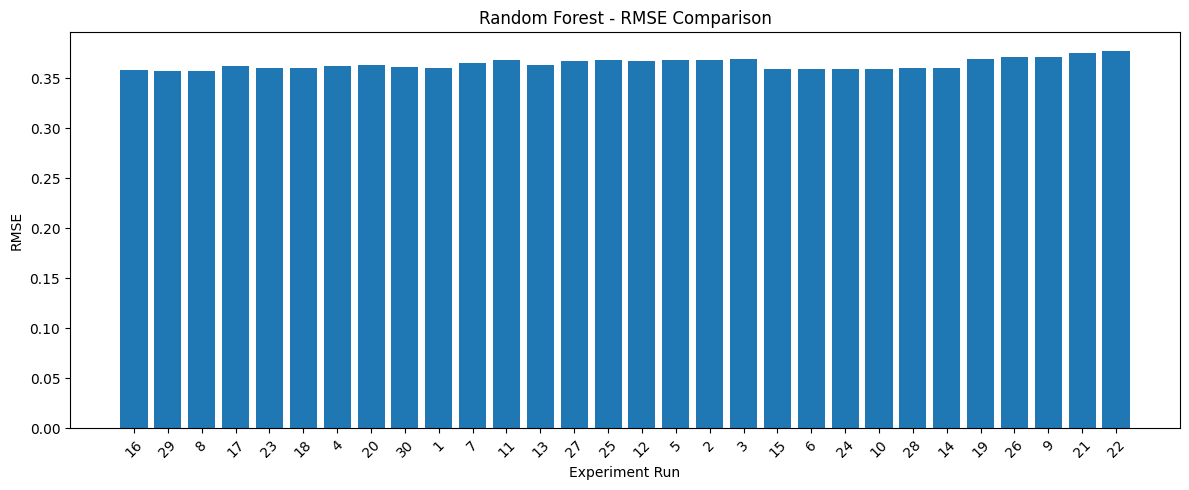

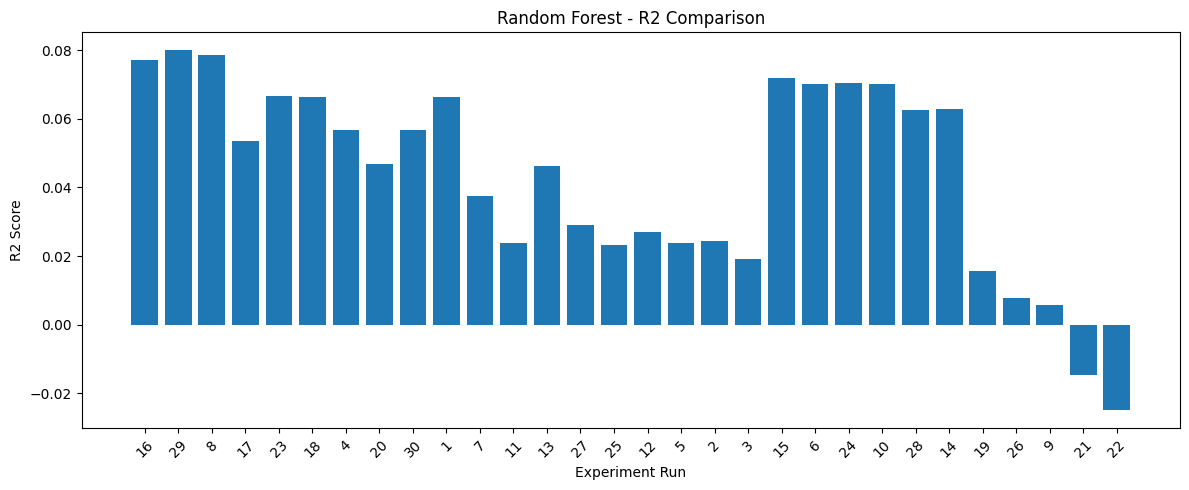

All three comparison graphs saved successfully.


In [16]:

import matplotlib.pyplot as plt
import os

GRAPH_DIR = f"{PROJECT_DIR}/results/graphs"
os.makedirs(GRAPH_DIR, exist_ok=True)

# 1. MAE Comparison
plt.figure(figsize=(12, 5))
plt.bar(results_df["Run"].astype(str), results_df["MAE"])
plt.xlabel("Experiment Run")
plt.ylabel("MAE")
plt.title("Random Forest - MAE Comparison")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{GRAPH_DIR}/mae_comparison.png")
plt.show()

# 2. RMSE Comparison
plt.figure(figsize=(12, 5))
plt.bar(results_df["Run"].astype(str), results_df["RMSE"])
plt.xlabel("Experiment Run")
plt.ylabel("RMSE")
plt.title("Random Forest - RMSE Comparison")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{GRAPH_DIR}/rmse_comparison.png")
plt.show()

# 3. R2 Comparison
plt.figure(figsize=(12, 5))
plt.bar(results_df["Run"].astype(str), results_df["R2"])
plt.xlabel("Experiment Run")
plt.ylabel("R2 Score")
plt.title("Random Forest - R2 Comparison")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{GRAPH_DIR}/r2_comparison.png")
plt.show()

print("All three comparison graphs saved successfully.")


In [20]:

import sqlite3
import os

DB_PATH = "/content/random_forest_backup/database/random_forest_tracking.db"
TEMP_DB = "/content/random_forest_tracking_backup.db"

# Create a consistent SQLite backup
source = sqlite3.connect(DB_PATH)
destination = sqlite3.connect(TEMP_DB)

source.backup(destination)

destination.close()
source.close()

# Replace the old backup with the verified database
os.replace(TEMP_DB, DB_PATH)

# Verify recovered experiment history
conn = sqlite3.connect(DB_PATH)

print("Experiments:")
print(conn.execute(
    "SELECT experiment_id, name FROM experiments"
).fetchall())

print("\nTotal MLflow Runs:")
print(conn.execute(
    "SELECT COUNT(*) FROM runs"
).fetchone()[0])

conn.close()


Experiments:
[(1, 'Automated_Answer_Grading_RandomForest'), (0, 'Default')]

Total MLflow Runs:
38


In [21]:

import os
import shutil
import sqlite3
import zipfile
from pathlib import Path

PROJECT = Path("/content/random_forest_backup")
DB = PROJECT / "database/random_forest_tracking.db"

# 1. Save both datasets
DATASET = PROJECT / "dataset"
DATASET.mkdir(parents=True, exist_ok=True)

train_df.to_csv(
    DATASET / "cleaned_ASAG2024_train(1).csv",
    index=False
)

test_df.to_csv(
    DATASET / "cleaned_ASAG2024_test.csv",
    index=False
)

# 2. Copy all original MLflow artifacts
SOURCE_ARTIFACTS = Path("/content/mlruns/1")
DEST_ARTIFACTS = PROJECT / "mlartifacts/1"

if SOURCE_ARTIFACTS.exists():
    shutil.copytree(
        SOURCE_ARTIFACTS,
        DEST_ARTIFACTS,
        dirs_exist_ok=True
    )

# 3. Update artifact locations in the backup database
conn = sqlite3.connect(DB)
cursor = conn.cursor()

cursor.execute(
    "UPDATE experiments SET artifact_location=? WHERE experiment_id=1",
    ((PROJECT / "mlartifacts/1").as_uri(),)
)

columns = [
    row[1] for row in cursor.execute(
        "PRAGMA table_info(runs)"
    ).fetchall()
]

run_id_column = "run_uuid" if "run_uuid" in columns else "run_id"

cursor.execute(
    f"SELECT {run_id_column} FROM runs WHERE experiment_id=1"
)

run_ids = [row[0] for row in cursor.fetchall()]

for run_id in run_ids:
    artifact_path = (
        PROJECT / "mlartifacts/1" / run_id / "artifacts"
    ).as_uri()

    cursor.execute(
        f"UPDATE runs SET artifact_uri=? WHERE {run_id_column}=?",
        (artifact_path, run_id)
    )

conn.commit()

total_runs = cursor.execute(
    "SELECT COUNT(*) FROM runs WHERE experiment_id=1"
).fetchone()[0]

conn.close()

# 4. Create Windows-compatible MLflow launcher
launcher = r'''
import sqlite3
import subprocess
from pathlib import Path

ROOT = Path(__file__).resolve().parent
DB = ROOT / "database" / "random_forest_tracking.db"
ARTIFACTS = ROOT / "mlartifacts"

conn = sqlite3.connect(DB)
cursor = conn.cursor()

cursor.execute(
    "UPDATE experiments SET artifact_location=? WHERE experiment_id=1",
    ((ARTIFACTS / "1").resolve().as_uri(),)
)

columns = [r[1] for r in cursor.execute(
    "PRAGMA table_info(runs)"
).fetchall()]

run_col = "run_uuid" if "run_uuid" in columns else "run_id"

cursor.execute(
    f"SELECT {run_col} FROM runs WHERE experiment_id=1"
)

for (run_id,) in cursor.fetchall():
    uri = (
        ARTIFACTS / "1" / run_id / "artifacts"
    ).resolve().as_uri()

    cursor.execute(
        f"UPDATE runs SET artifact_uri=? WHERE {run_col}=?",
        (uri, run_id)
    )

conn.commit()
conn.close()

print("Database and artifact paths configured.")

subprocess.run([
    "mlflow", "ui",
    "--backend-store-uri", f"sqlite:///{DB.as_posix()}",
    "--host", "127.0.0.1",
    "--port", "5000"
], cwd=str(ROOT), check=True)
'''

(PROJECT / "run_mlflow.py").write_text(launcher)

# 5. Recreate ZIP
ZIP_PATH = Path("/content/random_forest_backup.zip")

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(
    ZIP_PATH, "w", zipfile.ZIP_DEFLATED
) as z:
    for root, dirs, files in os.walk(PROJECT):
        dirs[:] = [d for d in dirs if d != "__pycache__"]

        for filename in files:
            path = Path(root) / filename
            z.write(path, path.relative_to(PROJECT.parent))

# 6. Final verification
print("\n========== BACKUP VERIFICATION ==========")
print("Experiment runs:", total_runs)
print("Training dataset:", (DATASET / "cleaned_ASAG2024_train(1).csv").exists())
print("External dataset:", (DATASET / "cleaned_ASAG2024_test.csv").exists())
print("Database:", DB.exists())
print("Best model:", (PROJECT / "models/best_model.pkl").exists())
print("MLflow artifacts:", DEST_ARTIFACTS.exists())
print("ZIP size:", round(ZIP_PATH.stat().st_size / (1024**2), 2), "MB")
print("ZIP:", ZIP_PATH)



========== BACKUP VERIFICATION ==========
Experiment runs: 38
Training dataset: True
External dataset: True
Database: True
Best model: True
MLflow artifacts: True
ZIP size: 3.19 MB
ZIP: /content/random_forest_backup.zip


In [22]:
from google.colab import files
files.download("/content/random_forest_backup.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>